Name : Aishi De Sec : A Sem : 7 PRN : 23070521008 Batch : A1

---



AIM : Stock Market Prediction using Recurrent Neural Networks. Problem Statement: Predict stock
price trends using historical NASDAQ stock data and RNN/LSTM models. Activities:
Prepare sequential data; Implement LSTM network; Visualize predicted vs actual values.

/tmp/ipykernel_1299/2997024013.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('AAPL', start='2019-01-01', end='2024-01-01')
[*********************100%***********************]  1 of 1 completed


Total trading days loaded: 1258


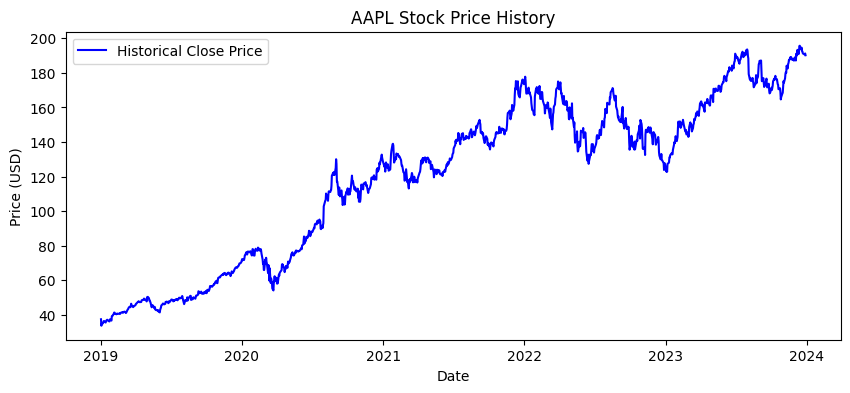

In [ ]:
!pip install yfinance -q

import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf

# Download 5 years of NASDAQ stock data (e.g., Apple: AAPL)
df = yf.download('AAPL', start='2019-01-01', end='2024-01-01')

# Extract Close price
data = df[['Close']].values
print(f"Total trading days loaded: {len(data)}")

# Preview raw stock prices
plt.figure(figsize=(10, 4))
plt.plot(df['Close'], color='blue', label='Historical Close Price')
plt.title('AAPL Stock Price History')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

In [ ]:
# 1. Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# 2. Train-Test Split (80% train, 20% test)
train_size = int(len(scaled_data) * 0.8)
train_data = scaled_data[:train_size]
test_data = scaled_data[train_size - 60:]  # include 60 timesteps overlap

# 3. Create time-series sliding windows (60 days lookback)
def create_sequences(dataset, time_step=60):
    X, y = [], []
    for i in range(time_step, len(dataset)):
        X.append(dataset[i - time_step:i, 0])
        y.append(dataset[i, 0])
    return np.array(X), np.array(y)

TIME_STEP = 60
X_train, y_train = create_sequences(train_data, TIME_STEP)
X_test, y_test = create_sequences(test_data, TIME_STEP)

# Reshape input to (samples, time_steps, features) for LSTM
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (946, 60, 1), y_train shape: (946,)
X_test shape: (252, 60, 1), y_test shape: (252,)


In [ ]:
# Build stacked LSTM model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(TIME_STEP, 1)),
    tf.keras.layers.LSTM(50, return_sequences=True),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(50, return_sequences=False),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(25),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

# Train the network
history = model.fit(
    X_train, y_train,
    batch_size=32,
    epochs=25,
    validation_data=(X_test, y_test)
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 218ms/step - loss: 0.0462 - val_loss: 0.0011
Epoch 2/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 139ms/step - loss: 0.0051 - val_loss: 9.9167e-04
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 0.0039 - val_loss: 0.0023
Epoch 4/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - loss: 0.0035 - val_loss: 0.0013
Epoch 5/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - loss: 0.0035 - val_loss: 0.0020
Epoch 6/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.0033 - val_loss: 9.1027e-04
Epoch 7/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0029 - val_loss: 0.0054
Epoch 8/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.0032 - val_loss: 9.8040e-04
Epoch 9/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - loss: 0.0025 - val_loss: 8.8211e-04
Epoch 10/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - loss: 0.0025 - val_loss: 0.0037
Epoch 11/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0027 - val_loss: 0.0011
Epoch 12/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 58

In [ ]:
import math
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Predict on test set
predictions = model.predict(X_test)

# Inverse transform to original USD scale
predictions = scaler.inverse_transform(predictions)
actual_prices = scaler.inverse_transform(y_test.reshape(-1, 1))

# Metrics evaluation
rmse = math.sqrt(mean_squared_error(actual_prices, predictions))
mae = mean_absolute_error(actual_prices, predictions)

print(f"\nRoot Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step

Root Mean Squared Error (RMSE): $5.10
Mean Absolute Error (MAE): $4.35


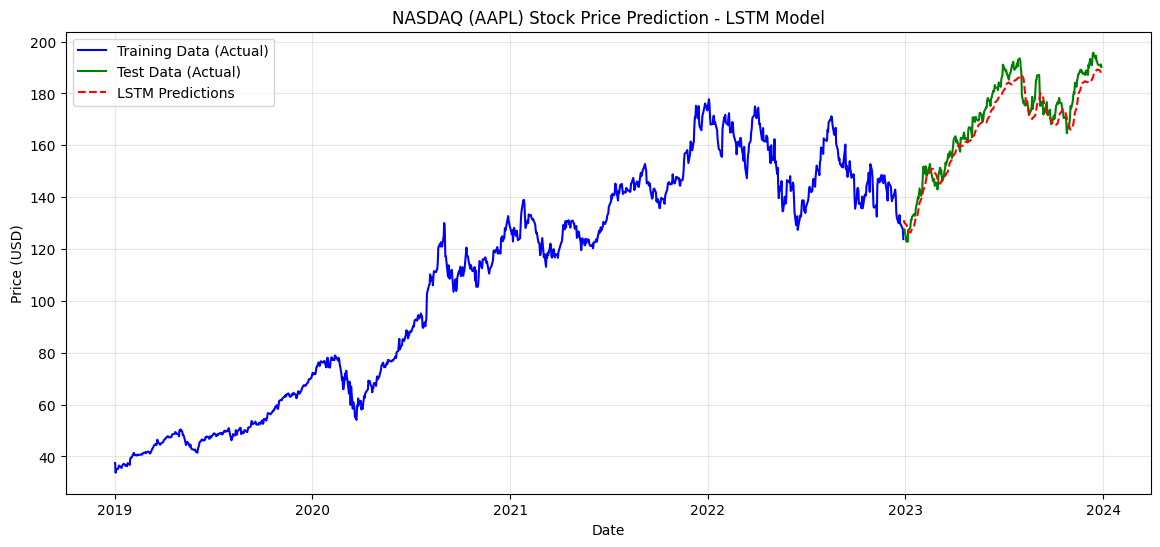

In [ ]:
# Prepare plotting dataframes
train_df = df.iloc[:train_size]
valid_df = df.iloc[train_size:].copy()
valid_df['Predictions'] = predictions

plt.figure(figsize=(14, 6))
plt.plot(train_df['Close'], label='Training Data (Actual)', color='blue')
plt.plot(valid_df['Close'], label='Test Data (Actual)', color='green')
plt.plot(valid_df['Predictions'], label='LSTM Predictions', color='red', linestyle='--')

plt.title('NASDAQ (AAPL) Stock Price Prediction - LSTM Model')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()